accuracy (test): 0.96


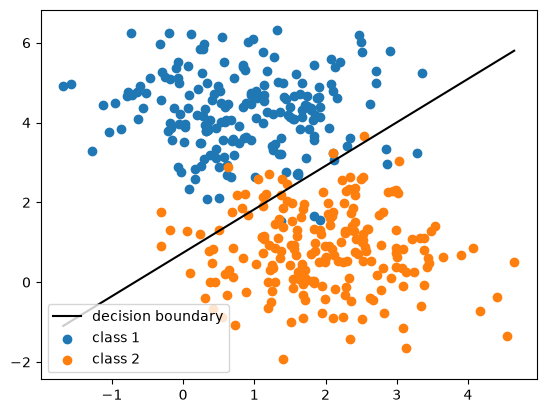

lr=1e-06   final NLL=   129.599  test acc=0.920
lr=1e-05   final NLL=    64.771  test acc=0.960
lr=0.0001  final NLL=    42.616  test acc=0.960
lr=0.001   final NLL=    37.635  test acc=0.950
lr=0.01    final NLL=    37.625  test acc=0.950


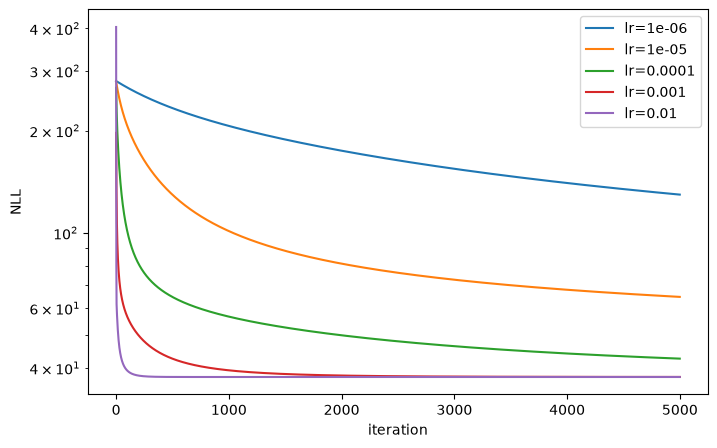

In [11]:
import numpy as np

# could be helpful for plotting:
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

# for evaluation
from sklearn.metrics import accuracy_score

"""
Task A:
Implement Logistic Regression and test on dataset2. Consider the TODOs, add functions or parameters if necessary.
"""

class LogisticRegression():

    def __init__(self):
        # TODO initialize all instance variables of the class
        self.w = None            # model parameters, w[0] is the bias
        
        self.nll_history = []    # NLL after every iteration (used in Task C)

    @staticmethod
    def _add_bias(X): # I added some helper functions to improve the code
        
        # bias trick: x -> (1, x1, x2)
        return np.hstack([np.ones((X.shape[0], 1)), X])

    @staticmethod
    def _sigmoid(t):
        
        t = np.clip(t, -500, 500)   # avoids overflow in exp
        
        return 1.0 / (1.0 + np.exp(-t))

    def _nll(self, Xb, y):
        p = self._sigmoid(Xb @ self.w)
        
        eps = 1e-12                  # avoids log(0)
        return -np.sum(y * np.log(p + eps) + (1 - y) * np.log(1 - p + eps))

    def fit(self, X, y, lr=0.0001, max_iter=1000, return_nll=False):
        """
        Parameter explanation
        ----------
        X : ndarray of shape (n_samples, n_features)
            Training feature matrix.
        y : ndarray of shape (n_samples,)
            Binary target labels (0 or 1).
        lr : float, default=0.0001
            Learning rate (= step size) for gradient descent updates.
        max_iter : int, default=1000
            Maximum number of gradient descent iterations.
        return_nll : bool, default=False
            If True, return the final negative log-likelihood value.
        --------
        """
        # TODO implement the training using gradient descent as discussed in the lecture
        #      you can simply run GD for a fixed number of iterations
        #      see the docstring above for explanations of the parameters
        Xb = self._add_bias(X)
        
        y = np.asarray(y).ravel()
        self.w = np.random.randn(Xb.shape[1]) * 0.01   # random initialization
        self.nll_history = []

        for _ in range(max_iter):
            p = self._sigmoid(Xb @ self.w)       # P(y=1|x)
            
            grad = Xb.T @ (p - y)                # gradient of the NLL
            self.w = self.w - lr * grad          # gradient descent step

            
            self.nll_history.append(self._nll(Xb, y))

        if return_nll:
            return self.nll_history              # NLL after every iteration

    def predict(self, X):
        # TODO implement the prediction step (X -> y)
        Xb = self._add_bias(X)
        
        return (self._sigmoid(Xb @ self.w) > 0.5).astype(int) ## y=1 if h(x) >= 0.5 and so on ...


dataset = np.load('dataset2.npz')

X_train = dataset['X_train']
X_test = dataset['X_test']


y_train = dataset['y_train']


y_test = dataset['y_test']

logreg = LogisticRegression()
logreg.fit(X_train, y_train, lr=1e-4, max_iter=500)
y_pred = logreg.predict(X_test)


print("accuracy (test):", accuracy_score(y_test, y_pred))


"""
Task B:
Write a function to plot the decision boundary, using the model coefficients.
The function can be specific for this dataset (2D input, binary classification).
"""
def plot_decision_boundary(model, X, y):
    # TODO: modify the following code such that the model's decision boundary is plotted
    # use the LogisticRegression model you fitted before and explicitly use the model parameters
    # to plot the decision boundary as a line

    # create the plot
    fig, ax = plt.subplots()

    # decision boundary: w0 + w1*x1 + w2*x2 = 0  ->  x2 = -(w0 + w1*x1) / w2
    w0, w1, w2 = model.w
    x1_vals = np.array([X[:, 0].min(), X[:, 0].max()])
    
    x2_vals = -(w0 + w1 * x1_vals) / w2


    
    ax.plot(x1_vals, x2_vals, c='black', label='decision boundary')

    # plot the data
    ax.scatter(X[y==0,0], X[y==0,1], label='class 1')
    ax.scatter(X[y==1,0], X[y==1,1], label='class 2')

    
    ax.set_ylim(X[:, 1].min() - 0.5, X[:, 1].max() + 0.5)   # keeps the line from rescaling the plot
    ax.legend()

    
    plt.show()


plot_decision_boundary(logreg, X_train, y_train)


"""
Task C:
Train Logistic Regression with different learning rates and plot
how the NLL changes during training. You might need to adapt the LogisticRegression class.
"""

lrs = [1e-6, 1e-5, 1e-4, 1e-3, 1e-2]

n_iter = 5000

plt.figure(figsize=(8, 5))
for lr in lrs:
    
    np.random.seed(0)                    # same initialization for every learning rate
    model = LogisticRegression()
    nll = model.fit(X_train, y_train, lr=lr, max_iter=n_iter, return_nll=True)

    
    plt.plot(nll, label=f"lr={lr}")
    print(f"lr={lr:<7} final NLL={nll[-1]:10.3f}  "
          f"test acc={accuracy_score(y_test, model.predict(X_test)):.3f}")

plt.xlabel("iteration")

plt.ylabel("NLL")
plt.yscale("log")

plt.legend()


plt.show()

## (a) Implement Logistic Regression as defined in the lecture slides, using only numpy. Then train and evaluate it on dataset2. How does the model perform? Hint: Use random initialization for w.

#### The accuracy of 0.96 was achieved by the model given lr = 1e-4, 500 iterations, random initialization of w; without a fixed seed the value varied between 0.95 and 0.96. Furthermore, the test set includes 100 points (55 of class 0, 45 of class 1) so always predicting the majority class gives us 0.55 and random guessing gives us around 0.5. The model performs far above the baseline and it can not reach 1.0 as the two classes have an overlap in the middle and a linear model cannot provide any separation for overlapping points. With only 100 points, one point is 1% accuracy.


## (b) Complete the function for plotting the decision boundary by using the model parameters to draw a line. How can you calculate the decision boundary from the model parameters? Use this funciton to create plots for Logistic Regression fitted on dataset2. What do you observe?


#### The model flags the point as class 1 if P(y=1|x) = sgd(w^T x) > 0.5. The sigmoid function is equal to 0.5 exactly when its input is 0 so the boundary is w^T x = 0. For instance, w0 + w1*x1 + w2*x2 = 0 that gives us x2 = -(w0 + w1*x1) / w2. This is a straight line. The vector (w1, w2) is the normal of the line and points to the class-1 side.


## (c) Run Gradient Descent with different step sizes η ∈ {10−6,10−5,10−4,10−3,10−2} on dataset2 and plot how the NLL changes over n1 iterations/ until convergence. What do you observe? Which step size is appropriate here?

#### Learning rates 1e-6 (final NLL 129.6) and 1e-5 (64.8) are not suitable since they are still decreasing after 5000 iterations so they are very slow. Even though lr = 1e-4 (42.6) is quite close but it is also still decreasing. 
#### Learning rates 1e-3 and 1e-2 reach a plateau at an NLL of about 37.6. After a few hundred iterations, 1e-2 gets there but it takes around 2000-3000 iterations for 1e-3.
#### The most suitable options are 1e-2 and 1e-3 since 1e-2 converges really fast and 1e-3 is more conservative to select and I would choose 1e-2.
#### As shown in the output the test accuracies are 0.92, 0.96, 0.96, 0.95, 0.95 for five sizes and it barely changes even when the NLL is far from its min. NLL is minimized by GD; therefore, the NLL curve is a good criterion for selecting the learning rate size. 1e-6 is the worst as the model is barely trained based on the plot.